# Proyecto Integrador · Avance I
## EDA y modelos preliminares de regresión y clasificación de homicidios en Ecuador

**Integrantes:** Liseth Simbaña, Oscar Lara y Anthony Pilamunga.

**Objetivo:** dar continuidad al EDA de Prácticas y Herramientas de Big Data para construir y evaluar **dos modelos** sobre los mismos datos y observaciones (cantón-día).

- **Parte A.** EDA, revisión de calidad, limpieza y conteos históricos.
- **Parte B.** Panel temporal compartido y modelo preliminar de **regresión** para predecir `victimas_homicidio` (cantidad).
- **Parte C.** Modelo preliminar de **clasificación** para predecir `hubo_victimas` (0 = no se registraron víctimas; 1 = se registró al menos una).
- **Parte D.** Análisis comparativo, limitaciones, conclusiones y exportaciones.


## Tema seleccionado
Se estudiarán los patrones espaciales y temporales de los homicidios intencionales en Ecuador. El proyecto propone relacionar sus registros históricos con los incidentes gestionados por el ECU 911 y con factores de calendario, como el día de la semana y los feriados. La unidad de análisis será cantón-día.


## Problemática y Referencias

Pregunta: ¿Cuántas víctimas de homicidio intencional se registrarían en un cantón el día siguiente, utilizando historia previa y calendario?

La fuente principal es Ministerio del Interior. ECU 911 aporta emergencias complementarias y la API aporta feriados. Una emergencia no equivale a un homicidio.

Referencias: https://www.datosabiertos.gob.ec/dataset/homicidios-intencionales ; https://www.datosabiertos.gob.ec/dataset/base-de-emergencias ; https://feriados.io/docs .

La unidad adoptada por el equipo es la víctima. Cada fila se contabiliza como una víctima registrada; varias pueden compartir características del hecho. Se debe incluir la referencia documental que respalda esta definición.

## Justificación problema y fuentes
La problemática tiene respaldo institucional. El ECU 911 informó que durante 2025 coordinó 3.239.683 emergencias, de las cuales 2.150.615 correspondieron a seguridad ciudadana. Su publicación también presenta diferencias entre cantones. Estas cifras justifican estudiar la distribución territorial de las emergencias y su posible utilidad como información complementaria; no constituyen el número de filas del archivo que utilizará el equipo ni equivalen a homicidios (Servicio Integrado de Seguridad ECU 911, 2026).

Asimismo, el Ministerio del Interior publica información estadística oficial de homicidios intencionales y reportó variaciones entre mayo de 2025 y mayo de 2026, aclarando el carácter preliminar del dato más reciente. Esto respalda la relevancia del fenómeno y la necesidad de documentar la versión y el corte de cada archivo antes de comparar periodos (Ministerio del Interior, 2026).

**Antecedentes e información disponible**

Existen registros administrativos de homicidios y de emergencias coordinadas, así como un proveedor de calendario que documenta soporte para Ecuador. Los documentos del equipo seleccionan estas fuentes para estudiar un problema territorial y temporal. Sin embargo, disponer de estadísticas oficiales no demuestra que los archivos concretos tengan cobertura completa a nivel cantón-día ni que la actividad del ECU 911 mejore una predicción.

**Aspecto por estudiar**

Se propone evaluar si los rezagos del conteo de homicidios, la actividad previa de emergencias y el calendario permiten describir patrones y, posteriormente, mejorar una estimación frente a una referencia simple. La relación entre ECU 911 y homicidios es una hipótesis de trabajo, no un resultado comprobado. Tampoco se asumirá que un feriado causa un aumento de violencia.

**Utilidad esperada**

Una respuesta permitiría contar con una base territorial y temporal reutilizable, un análisis transparente y, en etapas posteriores, estimaciones evaluadas para apoyar planificación. También sería útil concluir que una fuente no aporta capacidad predictiva o que su cobertura impide responder la pregunta: esas limitaciones orientan decisiones y evitan promesas sin evidencia.

### Características necesarias para el análisis

El dataset principal contiene registros de víctimas de homicidios intencionales. Para analizar su distribución por cantón y día, se consideran las siguientes características:

| Característica | Columnas relacionadas | ¿Qué representa? | ¿Por qué es útil? |
|---|---|---|---|
| Fecha de ocurrencia | fecha_infraccion | Fecha en la que ocurrió el hecho. | Permite ordenar los registros, contar víctimas por día y obtener variables de calendario. |
| Provincia | codigo_provincia, provincia | Provincia en la que ocurrió el hecho. | Permite identificar el territorio y comprobar la correspondencia con el cantón. |
| Cantón | codigo_canton, canton | Cantón en el que ocurrió el hecho. | Permite agrupar las víctimas territorialmente y relacionar posteriormente los datos con el ECU 911. |
| Tipo de muerte | tipo_muerte | Clasificación del homicidio registrada por la fuente. | Permite comprender las categorías incluidas y revisar su consistencia entre archivos. |
| Historial de víctimas | Conteo construido a partir de los registros | Número de víctimas registradas por cantón y día. | Permite definir la variable objetivo y construir información histórica para una futura etapa de Machine Learning. |
| Hora de ocurrencia | hora_infraccion | Hora en la que ocurrió el hecho. | Permite estudiar la distribución horaria de las víctimas. La hora del hecho futuro no se utilizará como entrada para predecir el total diario. |

Se revisarán los valores faltantes, los formatos de fecha, las categorías y la correspondencia entre códigos y nombres territoriales. Los códigos se conservarán como texto para mantener los ceros iniciales.

El conteo diario no es una columna original: se construirá agrupando los registros por fecha y territorio. Los atributos de las víctimas del día que se desea predecir, como edad, sexo o profesión, no se utilizarán como entradas del modelo porque se conocen después de ocurrido el hecho.

## Parte A · Análisis exploratorio y preparación
### A.1. Configuración y carga
Se leen los dos Excel una sola vez. Ajusta los nombres de archivo si difieren en Drive. No incorpores copias del mismo archivo como registros adicionales.


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# Detectar una sola pareja de archivos; no concatenar copias adicionales.
def localizar_archivos():
    carpetas = [
        Path.cwd(), Path.cwd() / "Homicidios", Path.cwd() / "upload",
        Path("/mnt/data"), Path("/content"),
        Path("/content/drive/MyDrive/Homicidios"),
    ]
    for carpeta in carpetas:
        if not carpeta.is_dir():
            continue
        historicos = sorted(carpeta.glob("mdi_homicidiosintencionales_pm_2014_2025*.xlsx"))
        actuales = sorted(carpeta.glob("mdi_homicidiosintencionales_pm_2026_enero_agosto*.xlsx"))
        if len(historicos) == 1 and len(actuales) == 1:
            return historicos[0], actuales[0]
    return None, None

archivo_historico, archivo_2026 = localizar_archivos()
if (archivo_historico is None or archivo_2026 is None) and EN_COLAB:
    drive.mount("/content/drive")
    archivo_historico, archivo_2026 = localizar_archivos()
if archivo_historico is None or archivo_2026 is None:
    raise FileNotFoundError(
        "Ubica ambos Excel en la carpeta del notebook, Homicidios, upload, /mnt/data "
        "o MyDrive/Homicidios (en Colab). Evita varias copias del mismo archivo en la carpeta."
    )

carpeta_homicidios = archivo_historico.parent
carpeta_salida = (
    Path("/content/drive/MyDrive/Resultados_911_Homicidios")
    if EN_COLAB and archivo_historico.as_posix().startswith("/content/drive/")
    else Path.cwd() / "Resultados_911_Homicidios"
)
carpeta_salida.mkdir(parents=True, exist_ok=True)

archivohistorio = pd.read_excel(archivo_historico, sheet_name="1. Homicidios Intencionales", dtype=str)
archivo2026homi = pd.read_excel(archivo_2026, sheet_name="1. Homicidios Intencionales", dtype=str)
for nombre, df in [("Histórico", archivohistorio), ("2026", archivo2026homi)]:
    print(nombre, df.shape)
    display(df.head())
    df.info()
if not archivohistorio.columns.equals(archivo2026homi.columns):
    raise ValueError("Revisa las diferencias de columnas antes de concatenar")
print("\nArchivos encontrados:", archivo_historico.name, "y", archivo_2026.name)

Mounted at /content/drive
Histórico (39821, 33)


,tipo_muerte,zona,subzona,distrito,circuito,codigo_subcircuito,subcircuito,codigo_provincia,provincia,codigo_canton,...,edad,medida_edad,sexo,genero,etnia,estado_civil,nacionalidad,discapacidad,profesion_registro_civil,instruccion
0,FEMICIDIO,ZONA 9,D.M. QUITO,QUITUMBE,TURUBAMBA,17D07C05S06,TURUBAMBA 6,17,PICHINCHA,1701,...,30,A,MUJER,FEMENINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
1,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVO GUAYAQUIL,09D08C06S01,NUEVO GUAYAQUIL 1,09,GUAYAS,0901,...,25,A,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
2,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVO GUAYAQUIL,09D08C06S01,NUEVO GUAYAQUIL 1,09,GUAYAS,0901,...,26,A,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
3,ASESINATO,ZONA 5,GUAYAS,EMPALME,EMPALME CENTRO,09D15C06S01,EMPALME CENTRO 1,09,GUAYAS,0908,...,21,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,TRABAJADOR GENERAL,SIN_DATO
4,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PORTETE,SUBURBIO,09D04C06S03,SUBURBIO 3,09,GUAYAS,0901,...,31,A,HOMBRE,MASCULINO,MESTIZO/A,DIVORCIADO,ECUADOR,NINGUNA,ESTADO PERSONAL,BACHILLERATO


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39821 entries, 0 to 39820
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   tipo_muerte               39821 non-null  object
 1   zona                      39821 non-null  object
 2   subzona                   39821 non-null  object
 3   distrito                  39821 non-null  object
 4   circuito                  39821 non-null  object
 5   codigo_subcircuito        39821 non-null  object
 6   subcircuito               39821 non-null  object
 7   codigo_provincia          39821 non-null  object
 8   provincia                 39821 non-null  object
 9   codigo_canton             39821 non-null  object
 10  canton                    39821 non-null  object
 11  coordenada_y              39821 non-null  object
 12  coordenada_x              39821 non-null  object
 13  area_hecho                39821 non-null  object
 14  lugar                 

,tipo_muerte,zona,subzona,distrito,circuito,codigo_subcircuito,subcircuito,codigo_provincia,provincia,codigo_canton,...,edad,medida_edad,sexo,genero,etnia,estado_civil,nacionalidad,discapacidad,profesion_registro_civil,instruccion
0,ASESINATO,ZONA 7,EL ORO,MACHALA,9 DE MAYO,07D02C01S01,9 DE MAYO 1,07,EL ORO,0701,...,33,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,TRABAJADOR GENERAL,SIN_DATO
1,ASESINATO,ZONA 1,ESMERALDAS,ESMERALDAS,AIRE LIBRE,08D01C03S01,AIRE LIBRE 1,08,ESMERALDAS,0801,...,50,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,TRABAJADOR GENERAL,SIN_DATO
2,ASESINATO,ZONA 8,D.M. GUAYAQUIL,FLORIDA,JUAN MONTALVO,09D06C04S04,JUAN MONTALVO 4,09,GUAYAS,0901,...,30,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,BACHILLER CIENCIAS,SIN_DATO
3,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PORTETE,PORTETE,09D04C04S04,PORTETE 4,09,GUAYAS,0901,...,48,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,TRABAJADOR PRIMARIO,SIN_DATO
4,ASESINATO,ZONA 1,IMBABURA,CIUDAD BLANCA,LAS LOMAS,10D01C09S01,LAS LOMAS 1,10,IMBABURA,1001,...,30,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,AYUDANTE/JORNALERO,BASICA


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5676 entries, 0 to 5675
Data columns (total 33 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   tipo_muerte               5676 non-null   object
 1   zona                      5676 non-null   object
 2   subzona                   5676 non-null   object
 3   distrito                  5676 non-null   object
 4   circuito                  5676 non-null   object
 5   codigo_subcircuito        5676 non-null   object
 6   subcircuito               5676 non-null   object
 7   codigo_provincia          5676 non-null   object
 8   provincia                 5676 non-null   object
 9   codigo_canton             5676 non-null   object
 10  canton                    5676 non-null   object
 11  coordenada_y              5676 non-null   object
 12  coordenada_x              5676 non-null   object
 13  area_hecho                5676 non-null   object
 14  lugar                   

### A.2. Procedencia y unidad de registro
Fuente principal: Ministerio del Interior DINASED. La hoja Contenido documenta cobertura y actualización; no confundir frecuencia de publicación con granularidad diaria. El equipo indica que la unidad es víctima. Varias víctimas pueden compartir fecha, hora y ubicación. No se reconstruyen sucesos únicos a partir de esos campos.


In [ ]:
for archivo in [archivo_historico, archivo_2026]:
    print("Metadatos:", archivo.name)
    display(pd.read_excel(archivo, sheet_name="Contenido", header=None).dropna(how="all"))

# Conservar originales y procedencia antes de unir
homicidios_originales = pd.concat([
    archivohistorio.assign(archivo_origen=archivo_historico.name),
    archivo2026homi.assign(archivo_origen=archivo_2026.name)
], ignore_index=True)
print("Total unificado:", homicidios_originales.shape)


Metadatos: mdi_homicidiosintencionales_pm_2014_2025 (2).xlsx


,0,1,2
2,NaN,Campo,Valor
3,NaN,Conjunto de Datos,Estadísticas de homicidios intencionales.
4,NaN,Pestaña,1. Homicidios Intencionales
5,NaN,Elaborado por,Dirección de Estadística y Economía de la Segu...
6,NaN,Descripción,Este conjunto de datos contiene información es...
7,NaN,Periodo de cobertura,2014 a 2025
8,NaN,Fecha actualización,18 de septiembre de 2026.
9,NaN,Fecha publicación,18 de septiembre de 2026.
10,NaN,Frecuencia de actualizacion,Mensual.
11,NaN,Fuentes,Ministerio del Interior-DINASED. Estadística d...


Metadatos: mdi_homicidiosintencionales_pm_2026_enero_agosto.xlsx


,0,1,2
2,NaN,Campo,Valor
3,NaN,Conjunto de Datos,Estadísticas de homicidios intencionales.
4,NaN,Pestaña,1. Homicidios Intencionales
5,NaN,Elaborado por,Dirección de Estadística y Economía de la Segu...
6,NaN,Descripción,Este conjunto de datos contiene información es...
7,NaN,Periodo de cobertura,enero a agosto de 2026
8,NaN,Fecha actualización,18 de septiembre de 2026.
9,NaN,Fecha publicación,18 de septiembre de 2026.
10,NaN,Frecuencia de actualizacion,Mensual.
11,NaN,Fuentes,Ministerio del Interior-DINASED. Estadística d...


Total unificado: (45497, 34)


### A.3. Revisión de calidad
No hay que borrar filas por faltantes en atributos opcionales. Los candidatos idénticos se conservan sin una clave individual que demuestre duplicación. Los conteos duplicados excluyen archivo_origen para comparar atributos de la fuente.


In [ ]:
for nombre, df in [("Histórico", archivohistorio), ("2026", archivo2026homi)]:
    print("\n", nombre)
    display(pd.DataFrame({"nulos": df.isna().sum(),
                          "SIN_DATO": df.eq("SIN_DATO").sum(),
                          "porcentaje_SIN_DATO": (df.eq("SIN_DATO").mean()*100).round(2)}))
    print("Repeticiones adicionales:", df.duplicated().sum())
    display(df.loc[df.duplicated(keep=False)].head(10))
    print("Categorías de tipo_muerte:")
    display(df.tipo_muerte.value_counts(dropna=False))
    print("Provincias:")
    display(df.provincia.value_counts(dropna=False))



 Histórico


,nulos,SIN_DATO,porcentaje_SIN_DATO
tipo_muerte,0,0,0.00
zona,0,0,0.00
subzona,0,0,0.00
distrito,0,0,0.00
circuito,0,0,0.00
codigo_subcircuito,0,0,0.00
subcircuito,0,0,0.00
codigo_provincia,0,0,0.00
provincia,0,0,0.00
codigo_canton,0,0,0.00


Repeticiones adicionales: 186


,tipo_muerte,zona,subzona,distrito,circuito,codigo_subcircuito,subcircuito,codigo_provincia,provincia,codigo_canton,...,edad,medida_edad,sexo,genero,etnia,estado_civil,nacionalidad,discapacidad,profesion_registro_civil,instruccion
137,ASESINATO,ZONA 4,MANABÍ,JIPIJAPA,PUERTO LÓPEZ,13D03C11S01,PUERTO LÓPEZ 1,13,MANABÍ,1319,...,SIN_DATO,SIN_DATO,NO DETERMINADO,NO APLICA,SIN_DATO,SIN_DATO,OTROS,NINGUNA,SIN_DATO,SIN_DATO
138,ASESINATO,ZONA 4,MANABÍ,JIPIJAPA,PUERTO LÓPEZ,13D03C11S01,PUERTO LÓPEZ 1,13,MANABÍ,1319,...,SIN_DATO,SIN_DATO,NO DETERMINADO,NO APLICA,SIN_DATO,SIN_DATO,OTROS,NINGUNA,SIN_DATO,SIN_DATO
380,ASESINATO,ZONA 7,EL ORO,PASAJE,RIO BONITO,07D01C06S01,RIO BONITO 1,07,EL ORO,0706,...,27,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,SIN_DATO
381,ASESINATO,ZONA 7,EL ORO,PASAJE,RIO BONITO,07D01C06S01,RIO BONITO 1,07,EL ORO,0706,...,27,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,SIN_DATO
436,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVA PROSPERINA,09D08C01S02,NUEVA PROSPERINA 2,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,NO DETERMINADO,NO APLICA,SIN_DATO,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
437,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVA PROSPERINA,09D08C01S02,NUEVA PROSPERINA 2,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,NO DETERMINADO,NO APLICA,SIN_DATO,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
438,ASESINATO,ZONA 8,D.M. GUAYAQUIL,NUEVA PROSPERINA,NUEVA PROSPERINA,09D08C01S02,NUEVA PROSPERINA 2,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,NO DETERMINADO,NO APLICA,SIN_DATO,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
613,ASESINATO,ZONA 7,EL ORO,MACHALA,GRAL SERRANO,07D02C06S01,GRAL SERRANO 1,07,EL ORO,0701,...,21,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,SIN_DATO
616,ASESINATO,ZONA 7,EL ORO,MACHALA,GRAL SERRANO,07D02C06S01,GRAL SERRANO 1,07,EL ORO,0701,...,21,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,SIN_DATO
632,ASESINATO,ZONA 8,D.M. GUAYAQUIL,FLORIDA,MAPASINGUE,09D06C06S02,MAPASINGUE 2,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO


Categorías de tipo_muerte:


...

,tipo_muerte,zona,subzona,distrito,circuito,codigo_subcircuito,subcircuito,codigo_provincia,provincia,codigo_canton,...,edad,medida_edad,sexo,genero,etnia,estado_civil,nacionalidad,discapacidad,profesion_registro_civil,instruccion
13,ASESINATO,ZONA 7,EL ORO,HUAQUILLAS,ARENILLAS,07D05C02S01,ARENILLAS 1,07,EL ORO,0702,...,28,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,BASICA
14,ASESINATO,ZONA 7,EL ORO,HUAQUILLAS,ARENILLAS,07D05C02S01,ARENILLAS 1,07,EL ORO,0702,...,28,A,HOMBRE,MASCULINO,MESTIZO/A,SOLTERO,ECUADOR,NINGUNA,ESTADO PERSONAL,BASICA
110,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PROGRESO,PROGRESO,09D10C03S01,PROGRESO 1,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
112,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PROGRESO,PROGRESO,09D10C03S01,PROGRESO 1,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
319,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PROGRESO,POSORJA,09D10C02S01,POSORJA 1,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
320,ASESINATO,ZONA 8,D.M. GUAYAQUIL,PROGRESO,POSORJA,09D10C02S01,POSORJA 1,09,GUAYAS,0901,...,SIN_DATO,SIN_DATO,HOMBRE,MASCULINO,MESTIZO/A,SIN_DATO,SIN_DATO,NINGUNA,SIN_DATO,SIN_DATO
360,ASESINATO,ZONA 5,SANTA ELENA,SANTA ELENA,MANANTIAL,24D01C06S01,MANANTIAL DE GUANGALA 1,24,SANTA ELENA,2401,...,20,A,HOMBRE,MASCULINO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO
361,ASESINATO,ZONA 5,SANTA ELENA,SANTA ELENA,MANANTIAL,24D01C06S01,MANANTIAL DE GUANGALA 1,24,SANTA ELENA,2401,...,20,A,HOMBRE,MASCULINO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO
362,ASESINATO,ZONA 5,SANTA ELENA,SANTA ELENA,MANANTIAL,24D01C06S01,MANANTIAL DE GUANGALA 1,24,SANTA ELENA,2401,...,20,A,HOMBRE,MASCULINO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO
363,ASESINATO,ZONA 5,SANTA ELENA,SANTA ELENA,MANANTIAL,24D01C06S01,MANANTIAL DE GUANGALA 1,24,SANTA ELENA,2401,...,20,A,HOMBRE,MASCULINO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO,SIN_DATO


Categorías de tipo_muerte:


,count
tipo_muerte,
ASESINATO,5392
HOMICIDIO,217
FEMICIDIO,44
SICARIATO,23


Provincias:


,count
provincia,
GUAYAS,2340
MANABÍ,839
EL ORO,788
LOS RÍOS,629
ESMERALDAS,228
PICHINCHA,183
SANTA ELENA,169
SUCUMBÍOS,100
ORELLANA,77


### Interpretación de los valores faltantes

No se encontraron valores nulos reconocidos por pandas en ninguno de los
dos archivos. Sin embargo, existen valores `SIN_DATO` que representan
información no disponible.

Las columnas necesarias para identificar la fecha y el territorio no
presentan nulos ni valores `SIN_DATO` en esta revisión. Se verificará
posteriormente la validez de las fechas y la consistencia territorial.

Los valores desconocidos se concentran en características personales,
especialmente instrucción y profesión. No se eliminarán registros por
faltantes en estas columnas, porque cada fila representa una víctima y
estos atributos no son necesarios para construir el conteo diario por cantón.

La hora de infracción presenta cinco valores `SIN_DATO` en el histórico.
Estos registros se conservarán para el análisis diario y se excluirán
únicamente de los análisis que requieran una hora conocida.

### Interpretación de repetidos
En las salidas anteriores se identificaron 186 repeticiones adicionales en el histórico y 45 en 2026 con duplicated(). Se conservan porque los atributos publicados no constituyen una clave individual de víctima.

### A.4. Limpieza justificada
Se convierten SIN_DATO y textos vacíos en faltantes, se normalizan espacios y mayúsculas territoriales y se convierten fechas. Se conservan los códigos como texto. Las filas sin fecha o territorio se separan y contabilizan; no se imputan. La hora se conserva para exploración.


In [ ]:
homicidios_limpios = homicidios_originales.copy()
homicidios_limpios = homicidios_limpios.replace(r"^\s*$", pd.NA, regex=True)
homicidios_limpios = homicidios_limpios.replace("SIN_DATO", pd.NA)
for columna in ["provincia", "canton", "tipo_muerte"]:
    homicidios_limpios[columna] = (homicidios_limpios[columna].astype("string")
                                  .str.strip().str.upper().str.replace(r"\s+", " ", regex=True))
for columna, longitud in [("codigo_provincia", 2), ("codigo_canton", 4)]:
    homicidios_limpios[columna] = homicidios_limpios[columna].astype("string").str.strip().str.zfill(longitud)
fechas = pd.to_datetime(homicidios_limpios.fecha_infraccion, format="mixed", dayfirst=True, errors="coerce")
print("Fechas no interpretables:", fechas.isna().sum())
display(homicidios_originales.loc[fechas.isna(), ["fecha_infraccion", "archivo_origen"]].head())
homicidios_limpios["fecha_infraccion"] = fechas.dt.normalize()
horas = pd.to_datetime(homicidios_limpios.hora_infraccion, format="%H:%M:%S", errors="coerce")
print("Horas no interpretables o desconocidas:", horas.isna().sum())
display(homicidios_limpios.loc[horas.isna(), ["hora_infraccion"]].drop_duplicates().head(20))
# No se elimina una víctima por falta de hora
homicidios_limpios["hora"] = horas.dt.hour
esenciales = ["fecha_infraccion", "codigo_provincia", "provincia", "canton", "codigo_canton"]
invalidas = homicidios_limpios[esenciales].isna().any(axis=1)
# Validar formato de códigos, además de su disponibilidad.
invalidas |= ~homicidios_limpios["codigo_provincia"].str.fullmatch(r"\d{2}").fillna(False)
invalidas |= ~homicidios_limpios["codigo_canton"].str.fullmatch(r"\d{4}").fillna(False)
rechazados = homicidios_limpios.loc[invalidas].copy()
homicidios_validos = homicidios_limpios.loc[~invalidas].copy()
print("Filas válidas:", len(homicidios_validos), "Separadas:", len(rechazados))
print("Rango de fechas observado:", homicidios_validos.fecha_infraccion.min(), homicidios_validos.fecha_infraccion.max())
revision_territorio = homicidios_validos.groupby("codigo_canton").agg(
    nombres=("canton", "nunique"), provincias=("provincia", "nunique"))
display(revision_territorio.loc[(revision_territorio.nombres > 1) | (revision_territorio.provincias > 1)])


Fechas no interpretables: 0


,fecha_infraccion,archivo_origen


Horas no interpretables o desconocidas: 5


,hora_infraccion
33804,<NA>


Filas válidas: 45497 Separadas: 0
Rango de fechas observado: 2014-01-01 00:00:00 2026-08-31 00:00:00


,nombres,provincias
codigo_canton,,


### A.5. Comparación antes y después
La conversión de SIN_DATO aumenta los nulos reconocidos; no significa que se haya perdido información. Las estadísticas se comparan sobre las mismas columnas originales. Los cambios territoriales o valores extremos requieren revisión, no eliminación automática.


In [ ]:
columnas_originales = archivohistorio.columns.tolist()
antes = homicidios_originales[columnas_originales]
despues = homicidios_validos[columnas_originales]
comparacion = pd.DataFrame({
    "indicador": ["Registros", "Columnas originales", "Repeticiones adicionales",
                  "Nulos reconocidos", "Textos SIN_DATO"],
    "antes": [len(antes), len(antes.columns), antes.duplicated().sum(),
              antes.isna().sum().sum(), antes.eq("SIN_DATO").sum().sum()],
    "despues": [len(despues), len(despues.columns), despues.duplicated().sum(),
                despues.isna().sum().sum(), despues.eq("SIN_DATO").sum().sum()]})
display(comparacion)
display(pd.DataFrame({"nulos_antes": antes.isna().sum(), "nulos_despues": despues.isna().sum(),
                      "tipo_antes": antes.dtypes.astype(str), "tipo_despues": despues.dtypes.astype(str),
                      "valores_distintos_antes": antes.nunique(), "valores_distintos_despues": despues.nunique()}))


,indicador,antes,despues
0,Registros,45497,45497
1,Columnas originales,33,33
2,Repeticiones adicionales,231,231
3,Nulos reconocidos,0,58602
4,Textos SIN_DATO,58602,0


,nulos_antes,nulos_despues,tipo_antes,tipo_despues,valores_distintos_antes,valores_distintos_despues
tipo_muerte,0,0,object,string,4,4
zona,0,0,object,object,9,9
subzona,0,0,object,object,26,26
distrito,0,0,object,object,141,141
circuito,0,0,object,object,935,935
codigo_subcircuito,0,0,object,object,1752,1752
subcircuito,0,0,object,object,1616,1616
codigo_provincia,0,0,object,string,24,24
provincia,0,0,object,string,24,24
codigo_canton,0,0,object,string,216,216


### A.6. Conteos y visualizaciones
Contamos víctimas por día observado y territorio. No se rellenan ceros todavía: un día sin filas puede requerir confirmación de cobertura. El histórico de 2026 es parcial. El ranking presenta conteos absolutos, no tasas de riesgo. Los días altos se investigan y no se descartan automáticamente.


,fecha_infraccion,codigo_provincia,provincia,codigo_canton,canton,victimas_homicidio
0,2014-01-01,01,AZUAY,0101,CUENCA,1
1,2014-01-01,02,BOLÍVAR,0201,GUARANDA,1
2,2014-01-01,04,CARCHI,0401,TULCÁN,2
3,2014-01-01,06,CHIMBORAZO,0601,RIOBAMBA,1
4,2014-01-01,07,EL ORO,0712,SANTA ROSA,1


,victimas_homicidio
count,27384.000000
mean,1.661445
std,1.907554
min,1.000000
25%,1.000000
50%,1.000000
75%,2.000000
max,125.000000


,fecha_infraccion,codigo_provincia,provincia,codigo_canton,canton,victimas_homicidio
7883,2021-09-28,09,GUAYAS,0901,GUAYAQUIL,125
8101,2021-11-12,09,GUAYAS,0901,GUAYAQUIL,65
9224,2022-05-09,23,STO DGO DE LOS TSÁCHILAS,2301,SANTO DOMINGO,46
6934,2021-02-23,09,GUAYAS,0901,GUAYAQUIL,40
23555,2025-11-09,07,EL ORO,0701,MACHALA,38
6929,2021-02-23,01,AZUAY,0101,CUENCA,34
20335,2025-03-06,09,GUAYAS,0901,GUAYAQUIL,29
13485,2023-07-23,09,GUAYAS,0901,GUAYAQUIL,26
22281,2025-08-10,09,GUAYAS,0901,GUAYAQUIL,23
15645,2024-01-01,09,GUAYAS,0907,DURÁN,22


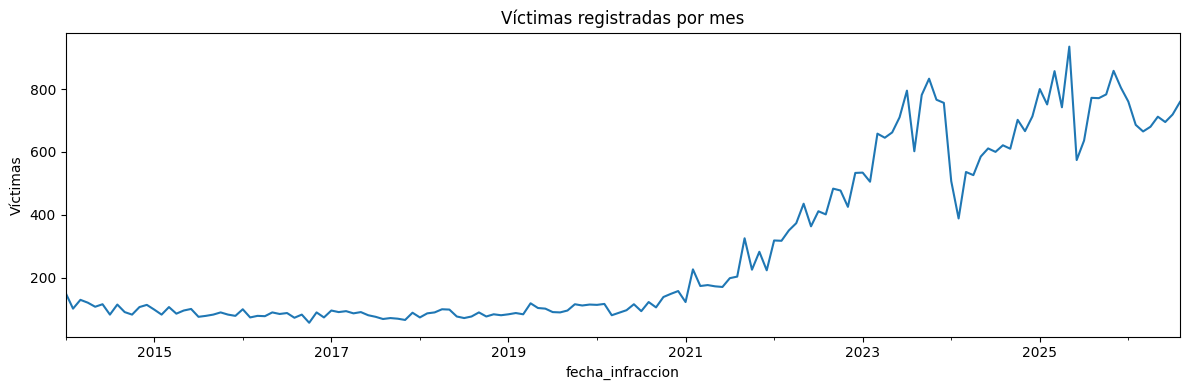

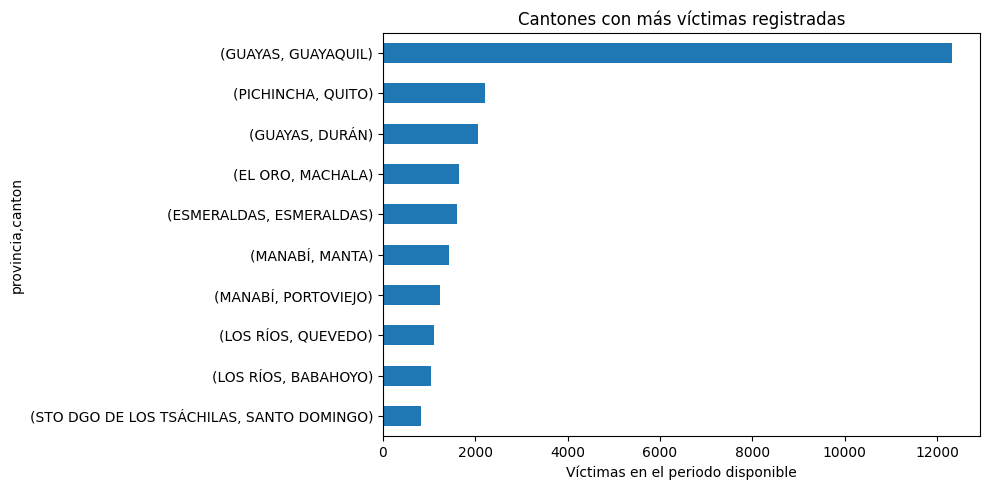

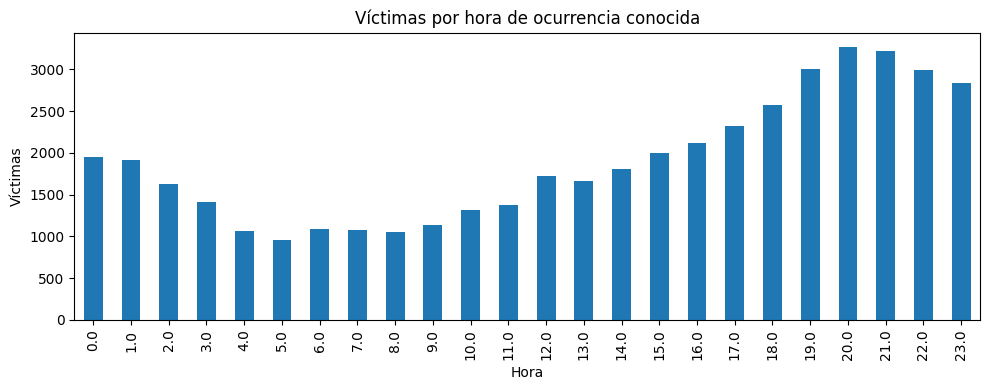

In [ ]:
victimas_diarias = (homicidios_validos.groupby(
    ["fecha_infraccion", "codigo_provincia", "provincia", "codigo_canton", "canton"])
    .size().reset_index(name="victimas_homicidio"))
assert victimas_diarias.victimas_homicidio.sum() == len(homicidios_validos)
display(victimas_diarias.head())
display(victimas_diarias.victimas_homicidio.describe())
display(victimas_diarias.nlargest(10, "victimas_homicidio"))
mensual = homicidios_validos.groupby(homicidios_validos.fecha_infraccion.dt.to_period("M")).size()
mensual.index = mensual.index.to_timestamp()
mensual.plot(figsize=(12,4), title="Víctimas registradas por mes", ylabel="Víctimas")
plt.tight_layout(); plt.show()
homicidios_validos.groupby(["provincia", "canton"]).size().nlargest(10).sort_values().plot.barh(
    figsize=(10,5), title="Cantones con más víctimas registradas")
plt.xlabel("Víctimas en el periodo disponible"); plt.tight_layout(); plt.show()
homicidios_validos.hora.value_counts().sort_index().plot.bar(
    figsize=(10,4), title="Víctimas por hora de ocurrencia conocida")
plt.xlabel("Hora"); plt.ylabel("Víctimas"); plt.tight_layout(); plt.show()


### Interpretación de resultados
Se obtuvieron **27.384** combinaciones de fecha y cantón con víctimas registradas. El **promedio** fue de **1,66 víctimas** por combinación, la **mediana** fue de **1** y el **máximo** fue de **125**. Este promedio no representa todos los días del calendario, porque la tabla todavía no incluye los días sin registros.

La gráfica mensual muestra conteos relativamente bajos entre **2014** y **2020**, seguidos de un incremento marcado desde 2021. Los mayores picos se observan entre 2023 y 2025. Para identificar los meses exactos con mayores conteos se debe consultar la tabla mensual. El archivo de 2026 cubre únicamente enero a agosto, por lo que su total anual no es directamente comparable con años completos. Esto no significa que agosto sea un mes incompleto.

Guayaquil concentra el mayor número acumulado de víctimas, seguido de Quito y Durán. También destacan Machala, Esmeraldas y Manta. Estos resultados corresponden a cantidades absolutas; no permiten concluir qué cantón tiene mayor riesgo por habitante sin incorporar datos de población.

En la distribución por hora, los mayores conteos se observan alrededor de las 20:00 y 21:00, mientras que los menores aparecen aproximadamente entre las 04:00 y 08:00. La gráfica considera únicamente registros con hora conocida. Este patrón es descriptivo y no demuestra que el horario sea la causa de los homicidios.

El mayor conteo diario corresponde a Guayaquil, el 28 de septiembre de 2021, con 125 víctimas. También destacan Guayaquil el 12 de noviembre de 2021, con 65, y Santo Domingo el 9 de mayo de 2022, con 46. Estos valores deben revisarse en los registros originales y contrastarse con fuentes oficiales. No deben eliminarse automáticamente como valores atípicos, ya que un hecho puede involucrar múltiples víctimas.

La limpieza permitió reconocer valores como SIN_DATO y espacios vacíos como información faltante, normalizar textos y códigos territoriales y convertir las fechas y horas a formatos adecuados para el análisis. Los registros repetidos se conservaron porque, sin un identificador individual, no puede asegurarse que correspondan a errores y no a víctimas diferentes.
En la ejecución revisada se conservaron 45.497 registros y no se separaron filas por claves esenciales inválidas. Se detectaron cinco horas desconocidas y no se encontraron códigos cantonales asociados a varios nombres o provincias. Estos controles no sustituyen una validación contra un catálogo territorial oficial.


### A.7. Variables candidatas y exportación
**y:** número de víctimas de homicidio intencional por cantón y día.

**X candidatas:** provincia y cantón como categorías, día de semana, mes, fin de semana y conteos históricos anteriores. Posteriormente se evaluarán feriados e historia del 911. El código cantonal es una clave territorial, no una cantidad numérica ordenada.

**Exclusiones:** atributos de la víctima y del hecho futuro, como edad, sexo, arma y motivación. No estarían disponibles antes de ese día. La hora sirve para explorar, pero la hora de un hecho futuro no se conoce.

En la parte A no se entrenan modelos; la parte B evalúa una primera regresión con calendario y territorio. Para crear rezagos se necesita un calendario diario completo confirmado por territorio; shift sobre días con registros omite días sin filas. El retraso de publicación debe considerarse antes de asumir disponibilidad del historial.


In [ ]:
victimas_diarias["dia_semana"] = victimas_diarias.fecha_infraccion.dt.dayofweek
victimas_diarias["mes"] = victimas_diarias.fecha_infraccion.dt.month
victimas_diarias["fin_semana"] = (victimas_diarias.dia_semana >= 5).astype(int)
display(victimas_diarias.head())
homicidios_validos.to_csv(carpeta_salida / "homicidios_unificados.csv.gz", index=False)
victimas_diarias.to_csv(carpeta_salida / "homicidios_conteos_diarios.csv.gz", index=False)
comparacion.to_csv(carpeta_salida / "comparacion_homicidios.csv", index=False)
rechazados[["fecha_infraccion", "provincia", "canton", "archivo_origen"]].to_csv(
    carpeta_salida / "homicidios_claves_rechazadas.csv", index=False)
print("Guardado en:", carpeta_salida)


,fecha_infraccion,codigo_provincia,provincia,codigo_canton,canton,victimas_homicidio,dia_semana,mes,fin_semana
0,2014-01-01,01,AZUAY,0101,CUENCA,1,2,1,0
1,2014-01-01,02,BOLÍVAR,0201,GUARANDA,1,2,1,0
2,2014-01-01,04,CARCHI,0401,TULCÁN,2,2,1,0
3,2014-01-01,06,CHIMBORAZO,0601,RIOBAMBA,1,2,1,0
4,2014-01-01,07,EL ORO,0712,SANTA ROSA,1,2,1,0


Guardado en: /content/drive/MyDrive/Resultados_911_Homicidios


### A.8. Conclusión del EDA

Los datos permiten avanzar en el análisis del número de víctimas de homicidios intencionales por cantón y día. Se unificaron los archivos históricos y de 2026, se revisaron los valores faltantes y las posibles repeticiones, y se estandarizaron fechas, textos y códigos territoriales. Además, se generaron conteos diarios y variables de calendario: día de la semana, mes y fin de semana.

El análisis exploratorio mostró un incremento marcado de las víctimas registradas desde 2021 y una mayor concentración acumulada en Guayaquil. También se observaron diferencias según la hora de ocurrencia. Estos resultados describen los registros disponibles, pero no demuestran relaciones causales ni capacidad predictiva.

La variable objetivo propuesta es `victimas_homicidio`. Como variables candidatas se consideran el cantón y las características del calendario. Posteriormente, se evaluará incorporar feriados mediante una API y conteos históricos del ECU911, utilizando información disponible antes de la fecha que se desea predecir.

Las principales limitaciones son la cobertura de 2026 únicamente hasta agosto, los valores registrados como `SIN_DATO` y la necesidad de verificar conteos extremos y posibles repeticiones. Los días sin registros no deben considerarse automáticamente como días con cero víctimas sin confirmar la cobertura de la fuente.

En esta etapa se obtuvo una base preparada para continuar el proyecto. La parte B desarrolla una primera regresión con territorio y calendario bajo un supuesto explícito para los ceros. La integración de fuentes complementarias y la verificación detallada de cobertura quedan como mejoras pendientes.


## Parte B · Avance I: regresión preliminar
### B.1. Objetivo, predictores y alcance
Se prepara un **panel único** compartido por los dos modelos. La regresión estima `victimas_homicidio` por cantón y día, incluyendo ceros. La clasificación, en la Parte C, utiliza `hubo_victimas`, derivada de esos mismos conteos. Los predictores iniciales son `codigo_canton`, `dia_semana`, `mes` y `dias_desde_inicio`: representan territorio, calendario y paso del tiempo. Su utilidad se comprobará mediante evaluación; no implica causalidad.

Se asume que la ausencia de registros dentro de la cobertura declarada representa cero víctimas **registradas**. Este supuesto no se demuestra con el mínimo y máximo de fechas. El alcance territorial se fija con los cantones presentes en 2014–2024 y puede excluir registros de otros cantones en prueba.

Entrenamiento: **2014–2024**. Prueba: **enero de 2025–agosto de 2026**. Se excluyen atributos del hecho futuro y el conteo del día de los predictores.

### B.2. Construcción del calendario y variable objetivo


In [ ]:
inicio = pd.Timestamp("2014-01-01")
fin = pd.Timestamp("2026-08-31")

cantones = (
    victimas_diarias.loc[
        victimas_diarias["fecha_infraccion"] < "2025-01-01",
        ["codigo_canton", "canton", "provincia"]
    ]
    .drop_duplicates()
)

if cantones["codigo_canton"].duplicated().any():
    raise ValueError(
        "Revisa la correspondencia entre códigos y territorios."
    )

fechas = pd.DataFrame({
    "fecha_infraccion": pd.date_range(inicio, fin)
})

calendario = fechas.merge(cantones, how="cross")

fecha_corte = pd.Timestamp("2025-01-01")

conteos = victimas_diarias[
    ["fecha_infraccion", "codigo_canton", "victimas_homicidio"]
].copy()

if conteos.duplicated(["fecha_infraccion", "codigo_canton"]).any():
    raise ValueError("Hay varios conteos para la misma fecha y código de cantón.")

# Contabilizar los registros que quedan fuera del alcance elegido.
fuera_alcance = conteos.loc[
    conteos["fecha_infraccion"].between(inicio, fin)
    & ~conteos["codigo_canton"].isin(cantones["codigo_canton"])
]
print("Combinaciones observadas fuera del alcance:", len(fuera_alcance))
print("Víctimas fuera del alcance:", fuera_alcance["victimas_homicidio"].sum())

# Ausencia de registros = cero solo bajo el supuesto de cobertura declarado.
datos_modelo = calendario.merge(
    conteos,
    on=["fecha_infraccion", "codigo_canton"],
    how="left",
    validate="one_to_one"
)

datos_modelo["victimas_homicidio"] = (
    datos_modelo["victimas_homicidio"].fillna(0).astype(int)
)

datos_modelo["dia_semana"] = (
    datos_modelo["fecha_infraccion"].dt.dayofweek
)

datos_modelo["mes"] = (
    datos_modelo["fecha_infraccion"].dt.month
)

datos_modelo["dias_desde_inicio"] = (
    datos_modelo["fecha_infraccion"] - inicio
).dt.days

conteos_incluidos = conteos.loc[
    conteos["fecha_infraccion"].between(inicio, fin)
    & conteos["codigo_canton"].isin(cantones["codigo_canton"])
]

assert (
    datos_modelo["victimas_homicidio"].sum()
    == conteos_incluidos["victimas_homicidio"].sum()
)

display(datos_modelo.head(10))

print("Cantones incluidos:", len(cantones))
print("Filas:", len(datos_modelo))
print(
    "Filas con cero víctimas:",
    datos_modelo["victimas_homicidio"].eq(0).sum()
)
print("Porcentaje de filas con cero:", round(datos_modelo["victimas_homicidio"].eq(0).mean() * 100, 2))


# Variable objetivo categórica, DERIVADA DEL MISMO PANEL que usa la regresión.
datos_modelo["hubo_victimas"] = (
    datos_modelo["victimas_homicidio"] > 0
).astype("int8")
assert (datos_modelo["hubo_victimas"] == (datos_modelo["victimas_homicidio"] > 0)).all()
assert datos_modelo[["victimas_homicidio", "hubo_victimas"]].notna().all().all()
print("Distribución de la clasificación (0=No / 1=Sí):")
display(pd.DataFrame({
    "cantón_días": datos_modelo["hubo_victimas"].value_counts().reindex([0, 1], fill_value=0),
    "porcentaje": (datos_modelo["hubo_victimas"].value_counts(normalize=True)
                   .reindex([0, 1], fill_value=0) * 100).round(2),
}).rename_axis("hubo_victimas"))

Combinaciones observadas fuera del alcance: 2
Víctimas fuera del alcance: 2


,fecha_infraccion,codigo_canton,canton,provincia,victimas_homicidio,dia_semana,mes,dias_desde_inicio
0,2014-01-01,0101,CUENCA,AZUAY,1,2,1,0
1,2014-01-01,0201,GUARANDA,BOLÍVAR,1,2,1,0
2,2014-01-01,0401,TULCÁN,CARCHI,2,2,1,0
3,2014-01-01,0601,RIOBAMBA,CHIMBORAZO,1,2,1,0
4,2014-01-01,0712,SANTA ROSA,EL ORO,1,2,1,0
5,2014-01-01,0801,ESMERALDAS,ESMERALDAS,1,2,1,0
6,2014-01-01,0901,GUAYAQUIL,GUAYAS,1,2,1,0
7,2014-01-01,0910,MILAGRO,GUAYAS,1,2,1,0
8,2014-01-01,0918,SANTA LUCÍA,GUAYAS,1,2,1,0
9,2014-01-01,1205,QUEVEDO,LOS RÍOS,3,2,1,0


Cantones incluidos: 215
Filas: 994590
Filas con cero víctimas: 967208
Porcentaje de filas con cero: 97.25
Distribución de la clasificación (0=No / 1=Sí):


,cantón_días,porcentaje
hubo_victimas,,
0,967208,97.25
1,27382,2.75


La tabla `datos_modelo` tiene una fila por fecha y cantón dentro del alcance. Los ceros se asignan según el supuesto de cobertura, no para sustituir fechas o territorios desconocidos de víctimas individuales. La suma se contrasta con los registros incluidos, y las exclusiones territoriales se informan por separado.


**Continuidad entre modelos:** de `victimas_homicidio` se deriva `hubo_victimas = 1` si el conteo es mayor que cero y `0` en caso contrario. La clasificación no inventa otra base ni modifica las víctimas originales.

### B.3. Separación temporal y revisión de faltantes
Se entrena con el pasado y se evalúa en fechas posteriores. Si los predictores no presentan faltantes, no se aplica imputación. Las transformaciones que aprenden parámetros se ajustan solo con entrenamiento.


In [ ]:
entrenamiento = datos_modelo.loc[
    datos_modelo["fecha_infraccion"] < "2025-01-01"
].copy()

prueba = datos_modelo.loc[
    datos_modelo["fecha_infraccion"] >= "2025-01-01"
].copy()

predictores = [
    "codigo_canton",
    "dia_semana",
    "mes",
    "dias_desde_inicio"
]

X_train = entrenamiento[predictores]
y_train = entrenamiento["victimas_homicidio"]

X_test = prueba[predictores]
y_test = prueba["victimas_homicidio"]

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

faltantes = pd.DataFrame({
    "entrenamiento": X_train.isna().sum(),
    "prueba": X_test.isna().sum()
})

display(faltantes)

if faltantes.to_numpy().sum() != 0:
    raise ValueError("Revisa los faltantes antes de entrenar.")
assert not entrenamiento.empty and not prueba.empty
assert entrenamiento["fecha_infraccion"].max() < prueba["fecha_infraccion"].min()
display(pd.DataFrame([
    {"conjunto": "Entrenamiento", "desde": entrenamiento["fecha_infraccion"].min(), "hasta": entrenamiento["fecha_infraccion"].max()},
    {"conjunto": "Prueba", "desde": prueba["fecha_infraccion"].min(), "hasta": prueba["fecha_infraccion"].max()}
]))


# Los dos modelos reutilizan exactamente estas fechas y filas.
assert len(entrenamiento) + len(prueba) == len(datos_modelo)

Entrenamiento: (863870, 4)
Prueba: (130720, 4)


,entrenamiento,prueba
codigo_canton,0,0
dia_semana,0,0
mes,0,0
dias_desde_inicio,0,0


,conjunto,desde,hasta
0,Entrenamiento,2014-01-01,2024-12-31
1,Prueba,2025-01-01,2026-08-31


### B.4. Codificación de predictores
Cantón, día y mes se tratan como categorías; el tiempo transcurrido se conserva como número. `fit_transform` aprende solo de entrenamiento y `transform` aplica lo aprendido a prueba.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

preparacion = ColumnTransformer([
    (
        "categorias",
        OneHotEncoder(drop="first", handle_unknown="ignore"),
        ["codigo_canton", "dia_semana", "mes"]
    ),
    (
        "tiempo",
        "passthrough",
        ["dias_desde_inicio"]
    )
])

X_train_preparado = preparacion.fit_transform(X_train)
X_test_preparado = preparacion.transform(X_test)

print("Entrenamiento preparado:", X_train_preparado.shape)
print("Prueba preparada:", X_test_preparado.shape)

Entrenamiento preparado: (863870, 232)
Prueba preparada: (130720, 232)


### B.5. Entrenamiento y predicciones
La regresión lineal estima cantidades medias y puede devolver decimales o negativos. Se conservan las predicciones originales para evaluar.


In [ ]:
modelo_regresion = LinearRegression()

modelo_regresion.fit(X_train_preparado, y_train)

predicciones = modelo_regresion.predict(X_test_preparado)

print("Modelo entrenado.")
print("Primeras predicciones:", predicciones[:10])

Modelo entrenado.
Primeras predicciones: [0.07518037 0.05226854 0.05301488 0.06172217 0.08709769 0.3363749
 2.09524701 0.14879505 0.05500512 0.24581911]


### B.6. Métricas y referencia
Se compara con el promedio histórico por cantón. Menor MSE y MAE es mejor; R² no es un porcentaje de aciertos y puede ser negativo.


In [ ]:
promedios = entrenamiento.groupby(
    "codigo_canton"
)["victimas_homicidio"].mean()

predicciones_base = prueba["codigo_canton"].map(promedios)

evaluacion = pd.DataFrame({
    "modelo": ["Promedio histórico", "Regresión lineal"],
    "MSE": [
        mean_squared_error(y_test, predicciones_base),
        mean_squared_error(y_test, predicciones)
    ],
    "MAE": [
        mean_absolute_error(y_test, predicciones_base),
        mean_absolute_error(y_test, predicciones)
    ],
    "R2": [
        r2_score(y_test, predicciones_base),
        r2_score(y_test, predicciones)
    ]
})

display(evaluacion.round(6))

resultados = prueba[
    ["fecha_infraccion", "codigo_canton", "canton", "victimas_homicidio"]
].copy()

resultados["prediccion"] = predicciones
resultados["prediccion_base"] = predicciones_base.to_numpy()
resultados["residual"] = (
    resultados["victimas_homicidio"] - resultados["prediccion"]
)

display(resultados.head(10))
print("Predicciones negativas:", (predicciones < 0).sum())

,modelo,MSE,MAE,R2
0,Promedio histórico,0.339637,0.118178,0.249051
1,Regresión lineal,0.333986,0.164796,0.261544


,fecha_infraccion,codigo_canton,canton,victimas_homicidio,prediccion,prediccion_base,residual
863870,2025-01-01,0101,CUENCA,0,0.075180,0.070931,-0.075180
863871,2025-01-01,0201,GUARANDA,0,0.052269,0.012444,-0.052269
863872,2025-01-01,0401,TULCÁN,0,0.053015,0.013191,-0.053015
863873,2025-01-01,0601,RIOBAMBA,0,0.061722,0.021901,-0.061722
863874,2025-01-01,0712,SANTA ROSA,1,0.087098,0.047287,0.912902
863875,2025-01-01,0801,ESMERALDAS,2,0.336375,0.296665,1.663625
863876,2025-01-01,0901,GUAYAQUIL,12,2.095247,2.056247,9.904753
863877,2025-01-01,0910,MILAGRO,0,0.148795,0.109009,-0.148795
863878,2025-01-01,0918,SANTA LUCÍA,0,0.055005,0.015182,-0.055005
863879,2025-01-01,1205,QUEVEDO,0,0.245819,0.206073,-0.245819


Predicciones negativas: 0


### B.7. Evaluación de días con y sin víctimas
Las métricas globales pueden ocultar errores en días con víctimas. Se comparan ambos grupos; no se calcula R² para el grupo de ceros porque su objetivo es constante.


In [ ]:
metricas_grupos = []

for grupo, condicion in [
    ("Sin víctimas", resultados["victimas_homicidio"] == 0),
    ("Con víctimas", resultados["victimas_homicidio"] > 0)
]:
    parte = resultados.loc[condicion]

    if parte.empty:
        continue

    for nombre, columna in [
        ("Promedio histórico", "prediccion_base"),
        ("Regresión lineal", "prediccion")
    ]:
        metricas_grupos.append({
            "grupo": grupo,
            "modelo": nombre,
            "filas": len(parte),
            "MSE": mean_squared_error(
                parte["victimas_homicidio"], parte[columna]
            ),
            "MAE": mean_absolute_error(
                parte["victimas_homicidio"], parte[columna]
            )
        })

evaluacion_grupos = pd.DataFrame(metricas_grupos)
display(evaluacion_grupos.round(6))


,grupo,modelo,filas,MSE,MAE
0,Sin víctimas,Promedio histórico,122845,0.002331,0.020650
1,Sin víctimas,Regresión lineal,122845,0.007377,0.073641
2,Con víctimas,Promedio histórico,7875,5.601399,1.639551
3,Con víctimas,Regresión lineal,7875,5.428883,1.586753


### B.8. Visualizaciones
La diagonal representa predicción perfecta. Residuales positivos indican subestimación y negativos sobreestimación.


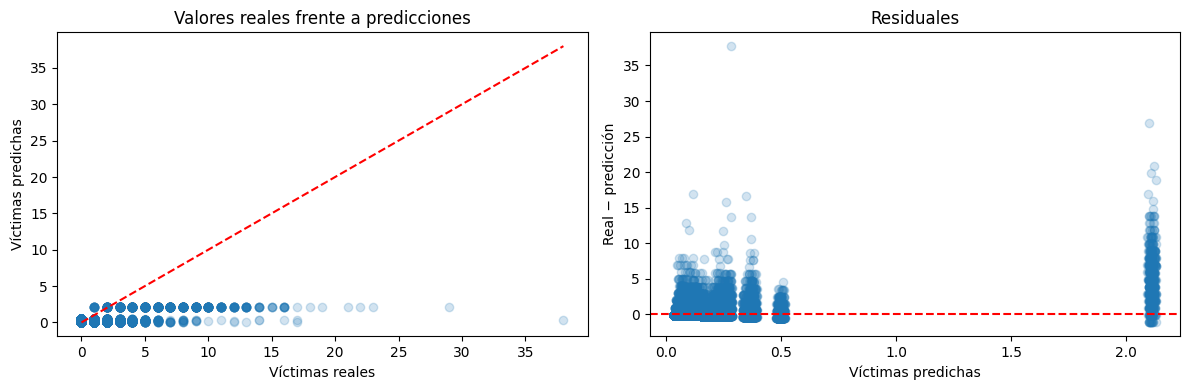

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_test, predicciones, alpha=0.2)

limite = max(y_test.max(), predicciones.max(), 1)
axes[0].plot([0, limite], [0, limite], "r--")

axes[0].set_title("Valores reales frente a predicciones")
axes[0].set_xlabel("Víctimas reales")
axes[0].set_ylabel("Víctimas predichas")

axes[1].scatter(
    resultados["prediccion"],
    resultados["residual"],
    alpha=0.2
)

axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residuales")
axes[1].set_xlabel("Víctimas predichas")
axes[1].set_ylabel("Real − predicción")

plt.tight_layout()
plt.show()

### B.9. Análisis de resultados
La siguiente celda resume las métricas de esta ejecución y su comparación con la referencia. Completa la interpretación de los gráficos: ¿se subestiman conteos altos?, ¿en qué grupo aumenta el error? Las métricas de regresión no se comparan directamente con accuracy o F1 de clasificación.


In [ ]:
tabla = evaluacion.set_index("modelo")
reg = tabla.loc["Regresión lineal"]
base = tabla.loc["Promedio histórico"]
print(f"Regresión: MSE={reg['MSE']:.6f}; MAE={reg['MAE']:.6f}; R²={reg['R2']:.6f}.")
print("¿Mejora MSE frente a la referencia?", reg["MSE"] < base["MSE"])
print("¿Mejora MAE frente a la referencia?", reg["MAE"] < base["MAE"])
print("¿Mejora R² frente a la referencia?", reg["R2"] > base["R2"])
print("Predicciones negativas:", int((predicciones < 0).sum()))
display(evaluacion_grupos.round(6))
# Investigar las mayores subestimaciones, sin eliminar esos registros.
display(resultados.nlargest(10, "residual"))


Regresión: MSE=0.333986; MAE=0.164796; R²=0.261544.
¿Mejora MSE frente a la referencia? True
¿Mejora MAE frente a la referencia? False
¿Mejora R² frente a la referencia? True
Predicciones negativas: 0


,grupo,modelo,filas,MSE,MAE
0,Sin víctimas,Promedio histórico,122845,0.002331,0.020650
1,Sin víctimas,Regresión lineal,122845,0.007377,0.073641
2,Con víctimas,Promedio histórico,7875,5.601399,1.639551
3,Con víctimas,Regresión lineal,7875,5.428883,1.586753


,fecha_infraccion,codigo_canton,canton,victimas_homicidio,prediccion,prediccion_base,residual
930964,2025-11-09,0701,MACHALA,38,0.284369,0.216526,37.715631
877636,2025-03-06,0901,GUAYAQUIL,29,2.099225,2.056247,26.900775
911391,2025-08-10,0901,GUAYAQUIL,23,2.117952,2.056247,20.882048
889891,2025-05-02,0901,GUAYAQUIL,22,2.105086,2.056247,19.894914
994166,2026-08-30,0901,GUAYAQUIL,21,2.126821,2.056247,18.873179
876991,2025-03-03,0901,GUAYAQUIL,19,2.094205,2.056247,16.905795
908387,2025-07-27,0908,EL EMPALME,17,0.117668,0.053758,16.882332
921280,2025-09-25,0801,ESMERALDAS,17,0.347782,0.296665,16.652218
873766,2025-02-16,0901,GUAYAQUIL,18,2.114157,2.056247,15.885843
920644,2025-09-22,0701,MACHALA,16,0.262655,0.216526,15.737345


### Interpretación de resultados

Se construyó una tabla de 994.590 combinaciones de fecha y cantón
para 215 cantones. El 97,25 % contiene cero víctimas registradas,
bajo el supuesto de cobertura declarado. Dos víctimas quedaron
fuera del alcance territorial del modelo, aunque se conservaron
en el dataset limpio.

El entrenamiento comprendió 2014–2024 y la prueba enero de 2025
a agosto de 2026. Los cuatro predictores no presentaron faltantes.
La codificación categórica generó 232 columnas de entrada.

La regresión obtuvo un MSE de 0,333986, un MAE de 0,164796 y un
R² de 0,261544. Mejoró ligeramente el MSE y el R² frente al
promedio histórico por cantón, pero empeoró el MAE global.
Por tanto, no fue superior en todas las métricas.

En las combinaciones con víctimas, el MAE disminuyó de 1,639551
a 1,586753. En las combinaciones sin víctimas, aumentó de
0,020650 a 0,073641. La abundancia de ceros hace necesario
interpretar las métricas generales junto con estos resultados
separados.

El modelo subestima algunos conteos elevados. Por ejemplo,
para Guayaquil el 1 de enero de 2025 predijo aproximadamente
2,10 víctimas frente a las 12 registradas. No se obtuvieron
predicciones negativas en prueba.

Los resultados cumplen el propósito de una aproximación
preliminar, pero no demuestran capacidad suficiente para uso
operativo. En próximas iteraciones se podrían evaluar modelos
para conteos y variables adicionales, seleccionando las mejoras
mediante validación temporal.

### B.10. Conclusión y mejoras
En la ejecución verificada, la regresión obtuvo MSE **0,333986**, MAE **0,164796** y R² **0,261544**. La referencia obtuvo MSE **0,339637**, MAE **0,118178** y R² **0,249051**. La regresión mejoró ligeramente MSE y R², pero empeoró MAE global.

En los **7.875 días-cantón con víctimas de prueba**, el MAE disminuyó de **1,639551** a **1,586753**. En los **122.845 días-cantón con cero**, aumentó de **0,020650** a **0,073642**. Esto explica por qué el resultado global no basta: el modelo mejora en el grupo con víctimas y empeora en el grupo de ceros. Las gráficas muestran subestimación de conteos elevados.

Se conservaron **45.497 víctimas** tras limpiar. El calendario utiliza **215 cantones** identificados en entrenamiento; **dos víctimas** quedan fuera de ese alcance territorial. Por eso la conservación del total del calendario se comprueba respecto de los registros incluidos, no del total nacional. Los resultados se deben volver a comprobar si cambian los archivos.

El modelo es una aproximación preliminar. Sus límites incluyen los ceros asumidos, el alcance territorial seleccionado, cambios temporales desde 2021 y la restricción de una regresión lineal con efectos aditivos. No se afirma capacidad suficiente para planificación operativa.

Se podrían evaluar modelos para conteos, tendencias distintas por cantón, periodos de entrenamiento más recientes y variables históricas disponibles antes de la predicción. Las decisiones se tomarían con validación temporal, reservando una prueba para la evaluación final. El conjunto de prueba actual ya fue inspeccionado y no debe presentarse como una nueva evaluación independiente después de ajustar el modelo con sus resultados.

Para la entrega conjunta falta incorporar la clasificación del equipo y explicar si comparte el mismo calendario, alcance y corte temporal. La clasificación «una frente a dos o más» sobre días con registros tiene un alcance diferente de esta regresión con ceros.


### B.11. Exportación de resultados
Se guardan la tabla usada, las métricas y las predicciones para reproducir y revisar el avance.


In [ ]:
carpeta_regresion = carpeta_salida / "Regresion"
carpeta_regresion.mkdir(parents=True, exist_ok=True)
datos_modelo.to_csv(carpeta_regresion / "tabla_modelo_regresion.csv.gz", index=False)
evaluacion.to_csv(carpeta_regresion / "metricas_regresion.csv", index=False)
evaluacion_grupos.to_csv(carpeta_regresion / "metricas_por_grupo.csv", index=False)
resultados.to_csv(carpeta_regresion / "predicciones_regresion.csv.gz", index=False)
print("Resultados guardados en:", carpeta_regresion)


Resultados guardados en: /content/drive/MyDrive/Resultados_911_Homicidios/Regresion


---

## Parte C · Modelo preliminar de clasificación binaria (0/1)

**Pregunta predictiva:** ¿en un cantón y fecha dados se registraría al menos una víctima de homicidio intencional?

- **Objetivo:** `hubo_victimas`, construido en la Parte B a partir de `victimas_homicidio`.
- **Clase 0:** no hay víctimas registradas en ese cantón-día del panel (cero inferido bajo el supuesto de cobertura).
- **Clase 1:** hay una o más víctimas registradas en ese cantón-día.
- **Variables predictoras:** `codigo_canton`, `dia_semana` y `mes`, disponibles antes de la fecha. El cantón aproxima heterogeneidad territorial; día y mes describen patrones de calendario. Ninguna variable del hecho futuro se utiliza como entrada.
- **Misma base y partición que regresión:** los 215 cantones seleccionados a partir de 2014–2024, entrenamiento de 2014–2024 y prueba de enero de 2025 a agosto de 2026. La clasificación utiliza tres predictores; la regresión añade `dias_desde_inicio` para representar una tendencia temporal. Ambos enfoques son preliminares.

Se utilizará regresión logística con ponderación de clases para contrarrestar el desbalance 0/1. Esta decisión puede aumentar los falsos positivos; sus puntuaciones no son probabilidades calibradas.

### C.1. Verificación de coherencia y selección de variables

La tabla del modelo de clasificación **no se reconstruye**. Se utilizan directamente `entrenamiento` y `prueba` creados para la regresión. Se comprueba que ambos conjuntos usan las mismas filas y que no hay valores faltantes en las entradas de clasificación.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
)

predictores_clasificacion = ["codigo_canton", "dia_semana", "mes"]
X_train_clas = entrenamiento[predictores_clasificacion].copy()
X_test_clas = prueba[predictores_clasificacion].copy()
y_train_clas = entrenamiento["hubo_victimas"].astype(int)
y_test_clas = prueba["hubo_victimas"].astype(int)

assert (y_train_clas == (entrenamiento["victimas_homicidio"] > 0)).all()
assert (y_test_clas == (prueba["victimas_homicidio"] > 0)).all()
assert (entrenamiento["fecha_infraccion"].max() < prueba["fecha_infraccion"].min())
assert not X_train_clas.isna().any().any() and not X_test_clas.isna().any().any()
assert set(y_train_clas.unique()) == {0, 1} and set(y_test_clas.unique()) == {0, 1}

print("Predictores de clasificación:", predictores_clasificacion)
print("Filas de entrenamiento:", len(X_train_clas), "| Filas de prueba:", len(X_test_clas))
print("Primera fecha de prueba:", prueba["fecha_infraccion"].min().date())
display(pd.DataFrame([
    {"conjunto": "Entrenamiento", "cantón_días": len(entrenamiento),
     "desde": entrenamiento.fecha_infraccion.min().date(),
     "hasta": entrenamiento.fecha_infraccion.max().date(),
     "porcentaje_clase_1": round(y_train_clas.mean()*100, 2)},
    {"conjunto": "Prueba", "cantón_días": len(prueba),
     "desde": prueba.fecha_infraccion.min().date(),
     "hasta": prueba.fecha_infraccion.max().date(),
     "porcentaje_clase_1": round(y_test_clas.mean()*100, 2)},
]))

Predictores de clasificación: ['codigo_canton', 'dia_semana', 'mes']
Filas de entrenamiento: 863870 | Filas de prueba: 130720
Primera fecha de prueba: 2025-01-01


,conjunto,cantón_días,desde,hasta,porcentaje_clase_1
0,Entrenamiento,863870,2014-01-01,2024-12-31,2.26
1,Prueba,130720,2025-01-01,2026-08-31,6.02


### C.2. Entrenamiento del modelo

El `OneHotEncoder` convierte territorio y calendario en variables indicadoras sin asignar una falsa magnitud a los códigos. Se ajusta dentro del pipeline **solo con entrenamiento**. `class_weight='balanced'` asigna más peso a la clase minoritaria. No se optimiza el umbral de clasificación utilizando la prueba.

In [ ]:
modelo_clasificacion = Pipeline([
    ("codificacion", OneHotEncoder(handle_unknown="ignore", dtype=np.float32)),
    ("clasificador", LogisticRegression(
        max_iter=1000, solver="liblinear", class_weight="balanced", random_state=42
    )),
])
modelo_clasificacion.fit(X_train_clas, y_train_clas)

referencia_clasificacion = DummyClassifier(strategy="most_frequent")
referencia_clasificacion.fit(X_train_clas, y_train_clas)
print("Modelo entrenado; clases:", modelo_clasificacion.named_steps["clasificador"].classes_)
print("Referencia: siempre predice la clase mayoritaria (0).")

Modelo entrenado; clases: [0 1]
Referencia: siempre predice la clase mayoritaria (0).


### C.3. Predicciones y métricas sobre el conjunto de prueba

Se calculan **accuracy, balanced accuracy, precisión, recall y F1**, todas sobre datos cronológicamente posteriores al entrenamiento. Precisión, recall y F1 tienen como clase positiva **1 = sí hubo víctimas registradas**. La referencia que predice siempre 0 sirve para mostrar por qué la accuracy puede ser engañosa cuando la mayoría de filas corresponde a ceros.

In [ ]:
y_pred_clas = modelo_clasificacion.predict(X_test_clas).astype(int)
y_pred_referencia_clas = referencia_clasificacion.predict(X_test_clas).astype(int)

metricas_clasificacion = pd.DataFrame([
    {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test_clas, pred),
        "Balanced accuracy": balanced_accuracy_score(y_test_clas, pred),
        "Precision (1)": precision_score(y_test_clas, pred, zero_division=0),
        "Recall (1)": recall_score(y_test_clas, pred, zero_division=0),
        "F1 (1)": f1_score(y_test_clas, pred, zero_division=0),
    }
    for nombre, pred in [
        ("Clase mayoritaria (0)", y_pred_referencia_clas),
        ("Regresión logística", y_pred_clas),
    ]
])
display(metricas_clasificacion.round(4))
print(classification_report(y_test_clas, y_pred_clas, labels=[0, 1],
    target_names=["0: sin víctimas registradas", "1: con víctimas registradas"],
    zero_division=0))

resultados_clasificacion = prueba[
    ["fecha_infraccion", "codigo_canton", "canton", "victimas_homicidio", "hubo_victimas"]
].copy()
resultados_clasificacion["prediccion_0_1"] = y_pred_clas
resultados_clasificacion["descripcion_prediccion"] = np.where(
    y_pred_clas == 1, "Sí: víctimas registradas", "No: sin víctimas registradas"
)
print("Ejemplos de predicciones positivas y negativas:")
display(pd.concat([
    resultados_clasificacion.loc[resultados_clasificacion.hubo_victimas == 0].head(5),
    resultados_clasificacion.loc[resultados_clasificacion.hubo_victimas == 1].head(5),
]).sort_values(["fecha_infraccion", "codigo_canton"]))

,Modelo,Accuracy,Balanced accuracy,Precision (1),Recall (1),F1 (1)
0,Clase mayoritaria (0),0.9398,0.5000,0.0000,0.0000,0.0000
1,Regresión logística,0.7993,0.8027,0.2045,0.8066,0.3262


                             precision    recall  f1-score   support

0: sin víctimas registradas       0.98      0.80      0.88    122845
1: con víctimas registradas       0.20      0.81      0.33      7875

                   accuracy                           0.80    130720
                  macro avg       0.59      0.80      0.60    130720
               weighted avg       0.94      0.80      0.85    130720

Ejemplos de predicciones positivas y negativas:


,fecha_infraccion,codigo_canton,canton,victimas_homicidio,hubo_victimas,prediccion_0_1,descripcion_prediccion
863870,2025-01-01,0101,CUENCA,0,0,1,Sí: víctimas registradas
863871,2025-01-01,0201,GUARANDA,0,0,0,No: sin víctimas registradas
863872,2025-01-01,0401,TULCÁN,0,0,0,No: sin víctimas registradas
863873,2025-01-01,0601,RIOBAMBA,0,0,0,No: sin víctimas registradas
863884,2025-01-01,0701,MACHALA,1,1,1,Sí: víctimas registradas
863874,2025-01-01,0712,SANTA ROSA,1,1,1,Sí: víctimas registradas
863875,2025-01-01,0801,ESMERALDAS,2,1,1,Sí: víctimas registradas
863876,2025-01-01,0901,GUAYAQUIL,12,1,1,Sí: víctimas registradas
863877,2025-01-01,0910,MILAGRO,0,0,1,Sí: víctimas registradas
863880,2025-01-01,1701,QUITO,1,1,1,Sí: víctimas registradas


### C.4. Matriz de confusión y visualización del desbalance

En la matriz, las filas son las categorías reales y las columnas son las categorías predichas:

- **Verdaderos negativos:** 0 real / 0 predicho.
- **Falsos positivos:** 0 real / 1 predicho (falsas alarmas).
- **Falsos negativos:** 1 real / 0 predicho (días con víctimas no detectados).
- **Verdaderos positivos:** 1 real / 1 predicho.

Las matrices del modelo y de la referencia se muestran con etiquetas 0 y 1.

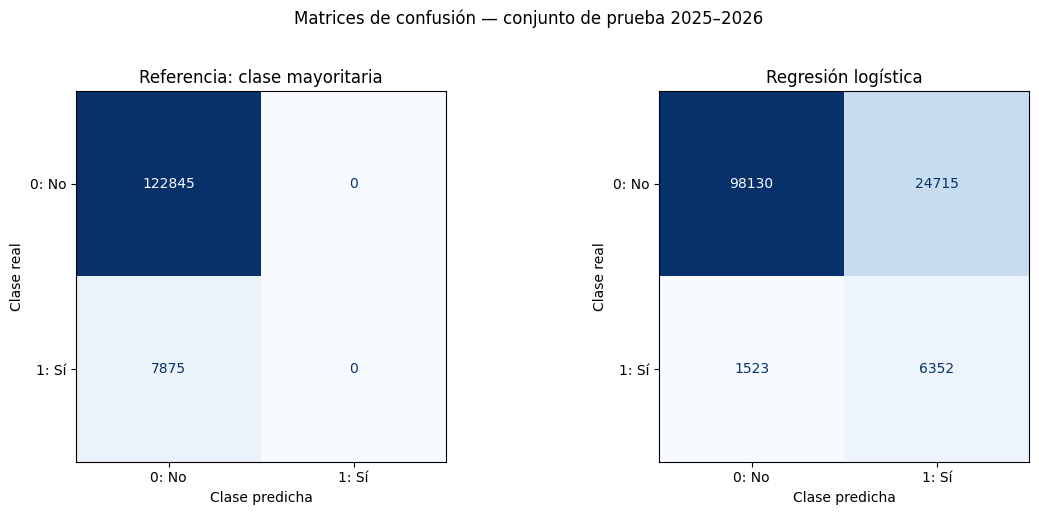

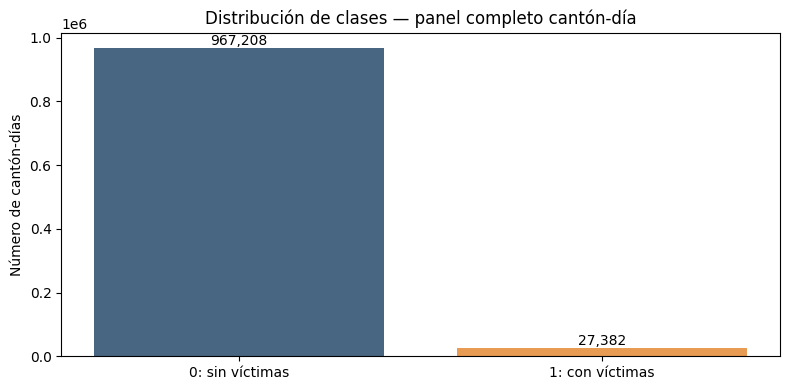

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, pred, titulo in [
    (axes[0], y_pred_referencia_clas, "Referencia: clase mayoritaria"),
    (axes[1], y_pred_clas, "Regresión logística"),
]:
    ConfusionMatrixDisplay.from_predictions(
        y_test_clas, pred, labels=[0, 1],
        display_labels=["0: No", "1: Sí"],
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(titulo)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
plt.suptitle("Matrices de confusión — conjunto de prueba 2025–2026", y=1.02)
plt.tight_layout()
plt.show()

matriz_clasificacion = confusion_matrix(y_test_clas, y_pred_clas, labels=[0, 1])
verdaderos_0, falsos_positivos, falsos_negativos, verdaderos_1 = matriz_clasificacion.ravel()

distribucion_clases = (datos_modelo["hubo_victimas"].value_counts()
                        .reindex([0, 1], fill_value=0))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(["0: sin víctimas", "1: con víctimas"], distribucion_clases.values,
       color=["#486581", "#E89B52"])
ax.set_title("Distribución de clases — panel completo cantón-día")
ax.set_ylabel("Número de cantón-días")
for i, n in enumerate(distribucion_clases.values):
    ax.text(i, n, f"{n:,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

### C.5. Interpretación de la clasificación

Las cifras que siguen se obtienen automáticamente de esta ejecución para evitar transcribir resultados de otra partición temporal. La ponderación puede aumentar la detección de la clase 1, a costa de más falsas alarmas. Un modelo que prediga siempre cero puede obtener mucha accuracy, pero su recall para la clase 1 es cero. Se interpretan **recall, precisión, F1 y matriz de confusión en conjunto**, y no como garantía de desempeño operativo.

In [ ]:
clas = metricas_clasificacion.set_index("Modelo").loc["Regresión logística"]
clas_base = metricas_clasificacion.set_index("Modelo").loc["Clase mayoritaria (0)"]
print("Resultados preliminares de CLASIFICACIÓN")
print(f"Accuracy = {clas['Accuracy']:.2%}, frente a {clas_base['Accuracy']:.2%} de la referencia.")
print(f"Balanced accuracy = {clas['Balanced accuracy']:.2%}.")
print(f"Precisión positiva = {clas['Precision (1)']:.2%}; recall positivo = {clas['Recall (1)']:.2%}; F1 positivo = {clas['F1 (1)']:.3f}.")
print(f"Verdaderos negativos = {verdaderos_0:,}; falsos positivos = {falsos_positivos:,}.")
print(f"Falsos negativos = {falsos_negativos:,}; verdaderos positivos = {verdaderos_1:,}.")
print("¿Detecta positivos que no detecta la referencia?:", "Sí" if verdaderos_1 > 0 else "No")
print("Limitación: los valores 0 del panel son inferidos; no constituyen verificación de ausencia real.")

Resultados preliminares de CLASIFICACIÓN
Accuracy = 79.93%, frente a 93.98% de la referencia.
Balanced accuracy = 80.27%.
Precisión positiva = 20.45%; recall positivo = 80.66%; F1 positivo = 0.326.
Verdaderos negativos = 98,130; falsos positivos = 24,715.
Falsos negativos = 1,523; verdaderos positivos = 6,352.
¿Detecta positivos que no detecta la referencia?: Sí
Limitación: los valores 0 del panel son inferidos; no constituyen verificación de ausencia real.


### C.6. Consultar una fecha y un código cantonal

La función permite realizar una predicción 0/1 con el modelo entrenado. **No afirma que un homicidio vaya a ocurrir**: ofrece una salida estadística exploratoria. Cuando la fecha está dentro del panel, se muestra además la etiqueta observada/inferida para comparación. La puntuación mostrada no está calibrada como probabilidad real.

In [ ]:
def predecir_presencia_victimas(codigo_canton, fecha):
    codigo = str(codigo_canton).strip().zfill(4)
    cantones_validos = set(cantones["codigo_canton"].astype(str))
    if codigo not in cantones_validos:
        raise ValueError("El código cantonal está fuera de los 215 cantones modelados.")
    fecha = pd.Timestamp(fecha).normalize()
    entrada = pd.DataFrame([{
        "codigo_canton": codigo,
        "dia_semana": int(fecha.dayofweek),
        "mes": int(fecha.month),
    }])
    predicho = int(modelo_clasificacion.predict(entrada)[0])
    puntuacion = float(modelo_clasificacion.predict_proba(entrada)[0, 1])
    salida = {
        "fecha": fecha.date().isoformat(),
        "codigo_canton": codigo,
        "prediccion_0_1": predicho,
        "interpretacion": "Sí: al menos una víctima registrada" if predicho == 1
                          else "No: cero víctimas registradas",
        "puntuacion_clase_1_no_calibrada": round(puntuacion, 4),
    }
    if inicio <= fecha <= fin:
        fila = datos_modelo.loc[
            (datos_modelo["fecha_infraccion"] == fecha)
            & (datos_modelo["codigo_canton"] == codigo), "hubo_victimas"
        ]
        if not fila.empty:
            salida["etiqueta_panel_0_1"] = int(fila.iloc[0])
    return pd.DataFrame([salida])

# Ejem
display(predecir_presencia_victimas("0901", "2026-08-15"))

,fecha,codigo_canton,prediccion_0_1,interpretacion,puntuacion_clase_1_no_calibrada,etiqueta_panel_0_1
0,2026-08-15,0901,1,Sí: al menos una víctima registrada,0.9874,1


---

## Parte D · Análisis integrado, limitaciones y conclusiones

### D.1. Comparación de modelos y variables

Ambos modelos comparten **la misma procedencia, limpieza, unidad cantón-día, territorios y separación temporal**. Se diferencian en el objetivo y el tipo de error:

| Aspecto | Regresión | Clasificación |
|---|---|---|
| Variable objetivo | `victimas_homicidio`, valor entero 0 o mayor | `hubo_victimas`, clase 0 o 1 |
| Qué responde | «¿Cuántas víctimas?» | «¿Se registrará alguna víctima?» |
| Predictores | Código cantonal, día, mes y días transcurridos | Código cantonal, día y mes |
| Algoritmo | Regresión lineal | Regresión logística, pesos balanceados |
| Referencia | Promedio histórico por cantón | Predecir siempre la clase más frecuente |
| Métricas | MSE, MAE y R² | Accuracy, balanced accuracy, precisión, recall y F1 |
| Gráficas | Reales vs. estimados y residuos | Matriz de confusión y distribución de clases |

El código de cantón refleja diferencias territoriales observadas, mientras que el calendario permite explorar patrones temporales. La regresión también contempla el avance del tiempo; en esta primera clasificación se mantuvieron los tres predictores originales para no introducir ajustes adicionales.

**No debe afirmarse que un modelo es “mejor” que el otro por comparar MSE con F1:** los objetivos y métricas son distintos. La evaluación común permite contrastar las fortalezas y limitaciones de cada enfoque para el mismo fenómeno.

In [ ]:
reg = evaluacion.set_index("modelo").loc["Regresión lineal"]
reg_base = evaluacion.set_index("modelo").loc["Promedio histórico"]
clas = metricas_clasificacion.set_index("Modelo").loc["Regresión logística"]
clas_base = metricas_clasificacion.set_index("Modelo").loc["Clase mayoritaria (0)"]

comparacion_final = pd.DataFrame([
    {"tipo": "Regresión", "modelo": "Regresión lineal", "objetivo": "Cantidad de víctimas",
     "metrica_principal": "MSE", "valor": reg["MSE"], "referencia": reg_base["MSE"]},
    {"tipo": "Regresión", "modelo": "Regresión lineal", "objetivo": "Cantidad de víctimas",
     "metrica_principal": "R²", "valor": reg["R2"], "referencia": reg_base["R2"]},
    {"tipo": "Clasificación", "modelo": "Regresión logística", "objetivo": "Presencia 0/1",
     "metrica_principal": "Recall (1)", "valor": clas["Recall (1)"], "referencia": clas_base["Recall (1)"]},
    {"tipo": "Clasificación", "modelo": "Regresión logística", "objetivo": "Presencia 0/1",
     "metrica_principal": "F1 (1)", "valor": clas["F1 (1)"], "referencia": clas_base["F1 (1)"]},
])
display(comparacion_final.round(4))

print(f"Misma población: {len(cantones)} cantones; {len(datos_modelo):,} cantón-días.")
print(f"Entrenamiento: {entrenamiento.fecha_infraccion.min().date()} a {entrenamiento.fecha_infraccion.max().date()}.")
print(f"Prueba: {prueba.fecha_infraccion.min().date()} a {prueba.fecha_infraccion.max().date()}.")
print(f"Regresión: MSE {reg['MSE']:.4f}, MAE {reg['MAE']:.4f}, R² {reg['R2']:.4f}.")
print(f"Clasificación: precision {clas['Precision (1)']:.2%}, recall {clas['Recall (1)']:.2%}, F1 {clas['F1 (1)']:.4f}.")
print("Comprobación de alineación de objetivos:",
      (datos_modelo["hubo_victimas"] == datos_modelo["victimas_homicidio"].gt(0)).all())

,tipo,modelo,objetivo,metrica_principal,valor,referencia
0,Regresión,Regresión lineal,Cantidad de víctimas,MSE,0.3340,0.3396
1,Regresión,Regresión lineal,Cantidad de víctimas,R²,0.2615,0.2491
2,Clasificación,Regresión logística,Presencia 0/1,Recall (1),0.8066,0.0000
3,Clasificación,Regresión logística,Presencia 0/1,F1 (1),0.3262,0.0000


Misma población: 215 cantones; 994,590 cantón-días.
Entrenamiento: 2014-01-01 a 2024-12-31.
Prueba: 2025-01-01 a 2026-08-31.
Regresión: MSE 0.3340, MAE 0.1648, R² 0.2615.
Clasificación: precision 20.45%, recall 80.66%, F1 0.3262.
Comprobación de alineación de objetivos: True


### D.2. Dificultades encontradas y mejoras futuras

**Preparación.** Se armonizaron códigos territoriales, fechas y marcadores `SIN_DATO` en dos Excel de periodos diferentes. Se preservaron posibles registros repetidos al no existir una clave individual que confirme duplicación. Los días sin filas se incorporaron como ceros **bajo un supuesto de cobertura** que debe verificarse. Se seleccionaron 215 cantones presentes en entrenamiento; quedan fuera del alcance del panel los registros de territorios nuevos en prueba, y esta exclusión se informa en la Parte B.

**Interpretación.** El conjunto tiene una mayoría muy marcada de ceros. Por ello, una regresión con error global pequeño puede subestimar episodios con múltiples víctimas y un clasificador con alta accuracy puede ignorar la clase 1. La comparación con referencias simples y las evaluaciones por clase evitan conclusiones exageradas.

**Iteraciones propuestas.** (1) Verificar cobertura diaria y cambios del catálogo territorial, (2) probar variables de historia de víctimas calculadas exclusivamente con días anteriores, (3) incorporar —si se obtienen con fechas y territorios comparables— señales históricas del ECU 911 y feriados, (4) probar modelos apropiados para conteos y alternativas de clasificación, (5) comparar resultados con validación temporal adicional, y (6) analizar si un umbral diferente mejora el equilibrio precisión-recall usando validación, nunca optimizando directamente sobre prueba.

### D.3. Conclusión

El proyecto cumple la construcción de **dos aproximaciones preliminares de Machine Learning** derivadas del EDA y del mismo dataset. La regresión predice cantidad de víctimas y la clasificación identifica presencia de registros (0/1). Se documentan los predictores, la limpieza, la división cronológica, las métricas, las gráficas y las limitaciones. Los valores de desempeño se muestran en la tabla calculada de la sección D.1, y deben interpretarse como evaluación exploratoria sobre el panel supuesto, no como un sistema validado para alertas reales.

### D.4. Exportación de entregables y reproducibilidad

Se guardan métricas y predicciones de ambos modelos, además de la tabla común en formato comprimido. Para repetir los resultados se necesitan los **dos archivos originales Excel** utilizados en la Parte A.

In [ ]:
carpeta_clasificacion = carpeta_salida / "Clasificacion"
carpeta_clasificacion.mkdir(parents=True, exist_ok=True)
metricas_clasificacion.to_csv(carpeta_clasificacion / "metricas_clasificacion.csv", index=False)
resultados_clasificacion.to_csv(
    carpeta_clasificacion / "predicciones_clasificacion.csv.gz", index=False
)
comparacion_final.to_csv(carpeta_salida / "comparacion_modelos.csv", index=False)
print("Carpeta de resultados:", carpeta_salida)
print("Métricas de clasificación:", carpeta_clasificacion / "metricas_clasificacion.csv")
print("Matriz de confusión 0/1:\n", matriz_clasificacion)

Carpeta de resultados: /content/drive/MyDrive/Resultados_911_Homicidios
Métricas de clasificación: /content/drive/MyDrive/Resultados_911_Homicidios/Clasificacion/metricas_clasificacion.csv
Matriz de confusión 0/1:
 [[98130 24715]
 [ 1523  6352]]
